In [1]:
import matplotlib.pyplot as plt
from analysis.io import load_dataset
import numpy as np
from analysis.enem_codes import INCOME_MIDPOINTS
import pandas as pd

In [2]:
d = load_dataset("enem")
X, y, names = d["X_train"], d["y_train"], d["feature_names"]

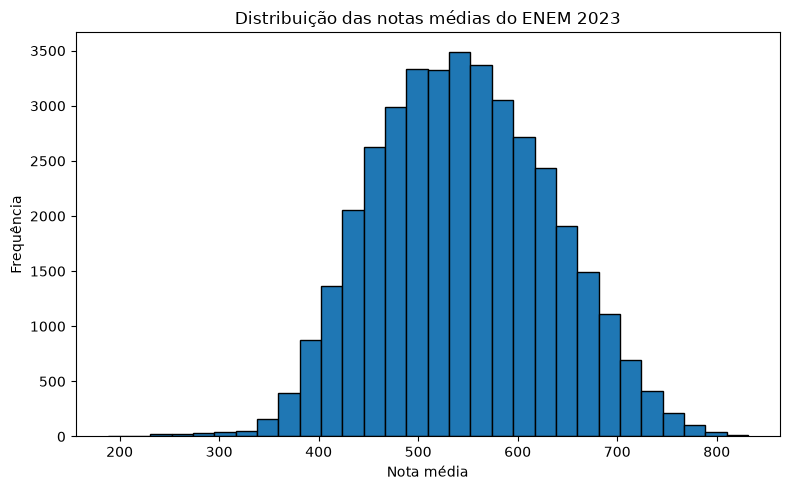

In [3]:
plt.figure(figsize=(8, 5))
plt.hist(y, bins=30, edgecolor="black")
plt.xlabel("Nota média")
plt.ylabel("Frequência")
plt.title("Distribuição das notas médias do ENEM 2023")
plt.tight_layout()
plt.show()

In [4]:
index = np.where(names == "school_3")[0][0]
school = X[:, index]

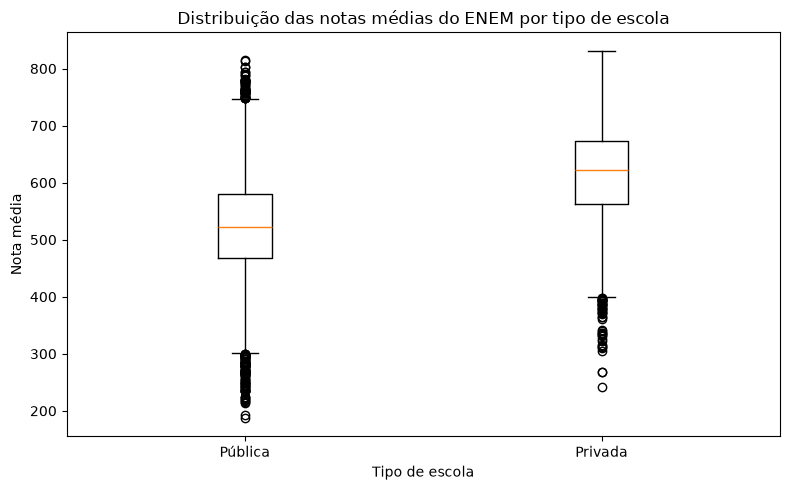

In [5]:
grades_by_school = [
    y[school == 0],
    y[school == 1]
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    grades_by_school,
    tick_labels=["Pública", "Privada"]
)
plt.xlabel("Tipo de escola")
plt.ylabel("Nota média")
plt.title("Distribuição das notas médias do ENEM por tipo de escola")
plt.tight_layout()
plt.show()

In [6]:
education_idx = np.where(names == "mother_education")[0][0]
unknown_education_idx = np.where(names == "mother_education_unknown")[0][0]
household_size_idx = np.where(names == "household_size")[0][0]
income_idx = np.where(names == "log_income_per_capita")[0][0]

education = X[:, education_idx].copy()
unknown_education = X[:, unknown_education_idx]
household_size = X[:, household_size_idx]
log_income_pc = X[:, income_idx]

household_income = household_size * np.expm1(log_income_pc)

print("Primeiras rendas reconstruídas:", household_income[:10])
print("Primeiras escolaridades:", education[:10])

Primeiras rendas reconstruídas: [4620. 2310. 2970. 4620.  660. 1650. 2310. 1650. 2310.    0.]
Primeiras escolaridades: [5. 4. 5. 1. 2. 3. 2. 4. 5. 0.]


In [7]:
income_midpoints = np.array(list(INCOME_MIDPOINTS.values()), dtype=float)
    
distances = np.abs(household_income[:, None] - income_midpoints[None, :])
category_indices = np.argmin(distances, axis=1)

income_midpoint = income_midpoints[category_indices] 

print("Maior diferença na reconstrução:",
      np.max(np.min(distances, axis=1)))

Maior diferença na reconstrução: 2.1827872842550278e-11


In [8]:
education_labels = {
    0: "Nunca estudou",
    1: "Não completou 4ª/5º ano",
    2: "Completou 4ª/5º ano, mas não 8ª/9º ano",
    3: "Completou 8ª/9º ano, mas não Ensino Médio",
    4: "Completou Ensino Médio, mas não faculdade",
    5: "Completou faculdade, mas não pós-graduação",
    6: "Completou pós-graduação",
}

known_education_mask = unknown_education == 0

education_label = np.array([
    education_labels[int(value)]
    for value in education[known_education_mask]
])

In [9]:
plot_df = pd.DataFrame({
    "nota_media": y[known_education_mask],
    "renda": income_midpoint[known_education_mask],
    "escolaridade_mae": education_label,
})

In [10]:
group_means = (
    plot_df
    .groupby(["renda", "escolaridade_mae"], observed=True)["nota_media"]
    .mean()
    .reset_index()
)

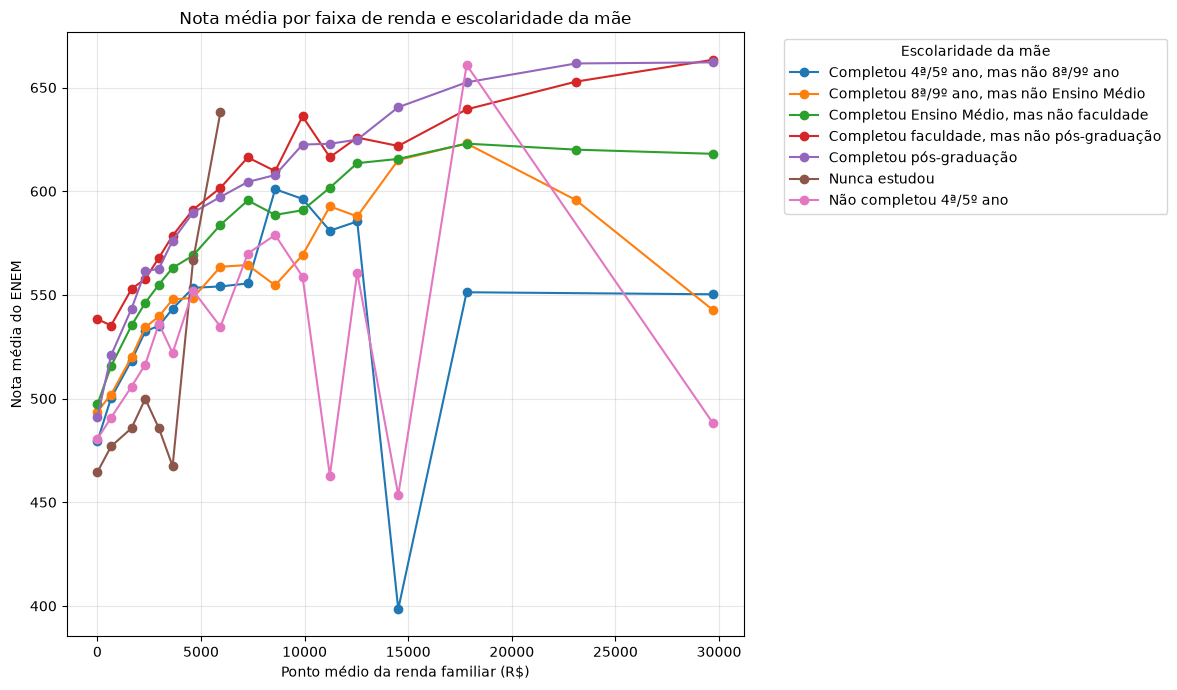

In [11]:
plt.figure(figsize=(12, 7))

for education, group in group_means.groupby("escolaridade_mae"):
    group = group.sort_values("renda")

    plt.plot(
        group["renda"],
        group["nota_media"],
        marker="o",
        label=education,
    )

plt.xlabel("Ponto médio da renda familiar (R$)")
plt.ylabel("Nota média do ENEM")
plt.title("Nota média por faixa de renda e escolaridade da mãe")
plt.legend(title="Escolaridade da mãe", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
asset_index_idx = np.where(names == "asset_index_1")[0][0]
asset_index = X[:, asset_index_idx]

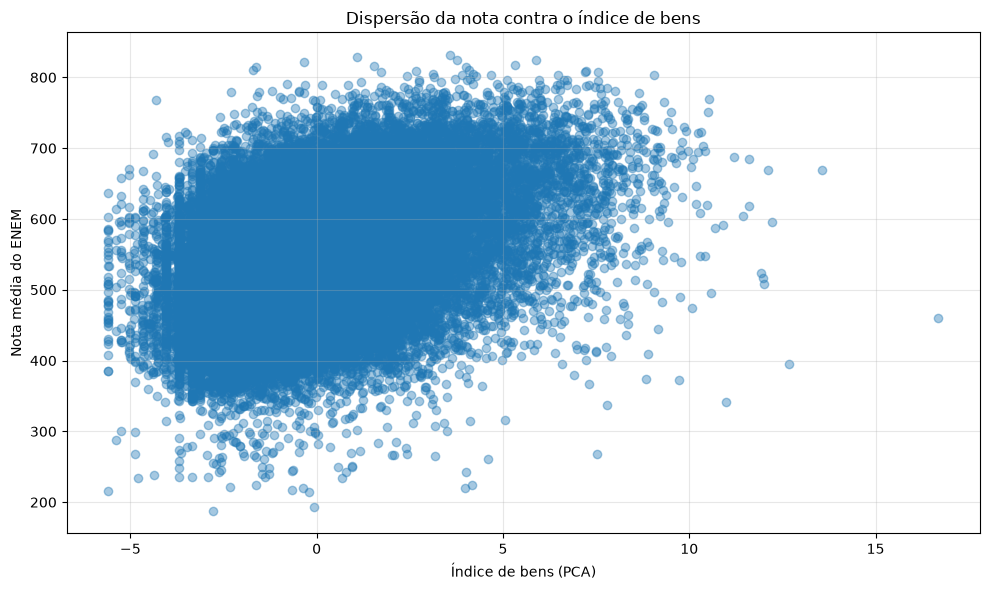

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(
    asset_index,
    y,
    alpha=0.4,
)

plt.xlabel("Índice de bens (PCA)")
plt.ylabel("Nota média do ENEM")
plt.title("Dispersão da nota contra o índice de bens")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
r = np.corrcoef(asset_index, y)[0, 1]

print(f"Correlação de Pearson: {r:.3f}")

Correlação de Pearson: 0.411
